<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/11_%E6%A8%A1%E5%9E%8B%E6%B3%9B%E5%8C%96/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 11. 模型泛化 (Model Generalization & K-Fold Cross Validation)

泛化能力是評估模型面對**從未見過新數據**時的實戰表現。
單次 `train_test_split` 容易受到切分運氣干擾（產生倖存者偏差）。
**K 折交叉驗證 (K-Fold Cross Validation)** 輪流以 $K$ 個子集測試，是檢驗泛化穩定度的黃金標準。

本範例讀取「鳶尾花繁體中文資料集」，執行 5 折交叉驗證並以 Seaborn 視覺化呈現！

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score

# 讀取繁體中文鳶尾花資料集
df = pd.read_csv('鳶尾花繁體中文資料集.csv')
features = ['花萼長度_公分', '花萼寬度_公分', '花瓣長度_公分', '花瓣寬度_公分']
X = df[features]
y = df['鳶尾花品種']

print("=== 鳶尾花資料集前瞻 ===")
display(df.head())


=== 鳶尾花資料集前瞻 ===


,花萼長度_公分,花萼寬度_公分,花瓣長度_公分,花瓣寬度_公分,鳶尾花品種
0,5.1,3.5,1.4,0.2,山鳶尾
1,4.9,3.0,1.4,0.2,山鳶尾
2,4.7,3.2,1.3,0.2,山鳶尾
3,4.6,3.1,1.5,0.2,山鳶尾
4,5.0,3.6,1.4,0.2,山鳶尾


In [4]:
# 執行 5 折交叉驗證
model = LogisticRegression(max_iter=300, random_state=42)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=kfold)

cv_df = pd.DataFrame({
    '驗證折數': [f'第 {i} 折' for i in range(1, 6)],
    '驗證準確率': scores * 100
})

print("=== 5 折交叉驗證結果 ===")
print(cv_df)
print(f"\n平均準確率 (Mean Accuracy): {scores.mean():.2%}")
print(f"分數標準差 (Standard Deviation): {scores.std():.4f}")


=== 5 折交叉驗證結果 ===
    驗證折數       驗證準確率
0  第 1 折  100.000000
1  第 2 折  100.000000
2  第 3 折   93.333333
3  第 4 折   96.666667
4  第 5 折   96.666667

平均準確率 (Mean Accuracy): 97.33%
分數標準差 (Standard Deviation): 0.0249


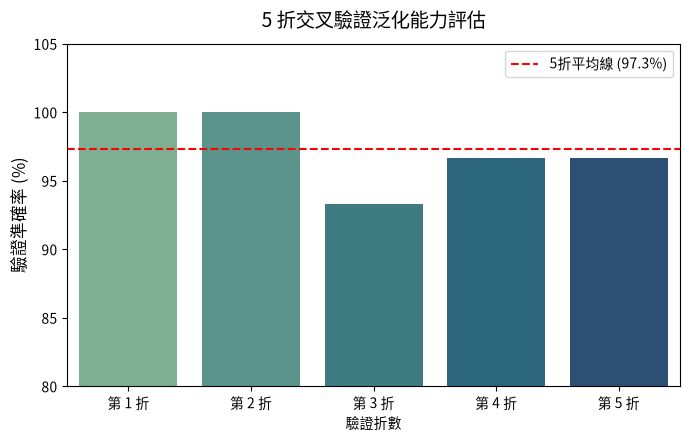

💡 觀念總結：標準差越小，代表模型面對未知變動資料時的表現越穩健可靠！


In [5]:
# 繪製各折準確率長條圖
plt.figure(figsize=(7, 4.5))
sns.barplot(data=cv_df, x='驗證折數', y='驗證準確率', hue='驗證折數', palette='crest', legend=False)
plt.axhline(scores.mean() * 100, color='red', linestyle='--', label=f'5折平均線 ({scores.mean():.1%})')
plt.title('5 折交叉驗證泛化能力評估', fontsize=14, pad=12)
plt.ylabel('驗證準確率 (%)', fontsize=12)
plt.ylim((80, 105))
plt.legend()
plt.tight_layout()
plt.show()

print("💡 觀念總結：標準差越小，代表模型面對未知變動資料時的表現越穩健可靠！")
